In [74]:
import numpy as np
#import lightkurve as lk
from astroquery.mast import Observations
import matplotlib.pyplot as plt
from astropy import units as u

from astropy.timeseries import LombScargle

from astropy.io import fits

%matplotlib inline

## Get obs from MAST


Currently:
* takes in TIC ID / sector
* downloads matching TESS-SPOC LC
* returns local path to file

Improvements:
* "functionalize" the code
* this could be run without downloads on TIKE (limited application when there are so few targets?)

In [2]:
obs = Observations.query_criteria(target_name=442871031
                                  , provenance_name='TESS-SPOC'
                                  , sequence_number=32)
prod = Observations.get_product_list(obs)
lc = Observations.download_products(prod[0])

fits_path = lc['Local Path'][0]

INFO: Found cached file ./mastDownload/HLSP/hlsp_tess-spoc_tess_phot_0000000442871031-s0032_tess_v1_tp/hlsp_tess-spoc_tess_phot_0000000442871031-s0032_tess_v1_lc.fits with expected size 406080. [astroquery.query]


## Parse Quality Flags

Given a fits path, read in the data and then keep only the data suitable for anaylsis.

In [3]:
def parse_quality(fits_path):
    ''' Read in a fits path, output the times / fluxes
    (remove the "bad quality" values from both)
    '''
    with fits.open(fits_path, mode="readonly") as hdulist:
        tmz = hdulist[1].data['TIME']
        sap_fluxes = hdulist[1].data['SAP_FLUX']
        quality = hdulist[1].data['QUALITY']

    bad_bits = np.array([1,2,3,4,5,6,8,10,12,13,15])
    value = 0
    for v in bad_bits:
        value = value + 2**(v-1)

    bad_data = np.bitwise_and(quality, value) >= 1 
    return tmz[~bad_data], sap_fluxes[~bad_data]

In [5]:
tmz, sap_fluxz = parse_quality(fits_path)

## Generate Preview / Periodogram Plots

Take in the cleaned data from above, generate a periodogram. Then make some plots

To do:
* LombScargle frequencies need to be determined, rather than set. 
  * Lower limit on frequencies comes from TESS sampling rate (nyquist)
  * Upper limit on freq comes from length of data, we need at least two full periods to determine
* Add period axis to the top

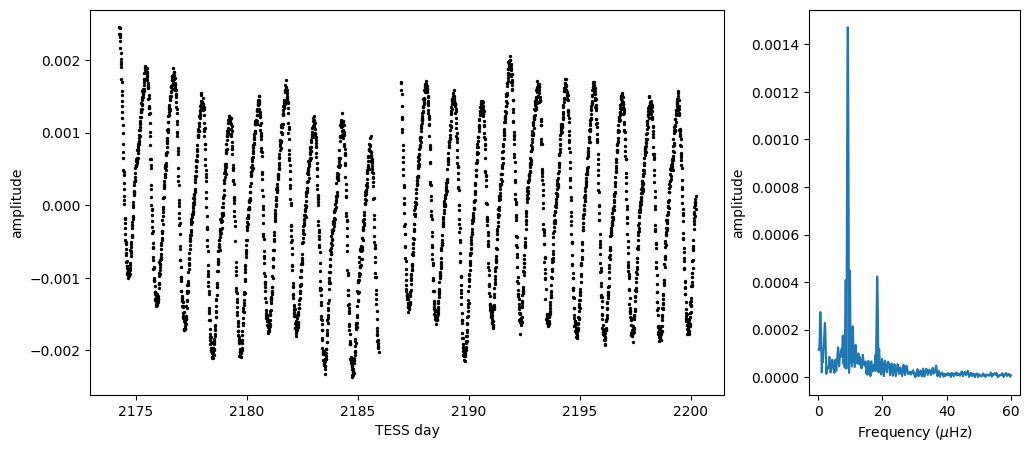

In [82]:
def make_pgrm(t, f):
    f_norm = f/np.median(f)
    # get right units for LS, make input freqs
    t = t*u.day
    freqs = np.linspace(0.1, 60, 50000) * u.microhertz
    
    # do psd lombscarge with special correction to get amplitude
    pwrs = LombScargle(t, f_norm, normalization='psd').power(freqs)
    pwrs = np.sqrt(pwrs) * np.sqrt(4.0 / len(t))
    return freqs, pwrs
    

def make_plots(t, f, freqs, pwrs):
    f_norm = f/np.median(f)
    fig, (ax1,ax2) = plt.subplots(1,2, figsize=(12,5), gridspec_kw={'width_ratios':[3,1]})
    # plot lc
    ax1.scatter(t
            ,f_norm-1
            ,c='black'
            ,s=2)
    ax1.set_xlabel('TESS day')
    ax1.set_ylabel('amplitude')
    
    # plot prgm
    ax2.plot(freqs, pwrs)
    ax2.set_xlabel('Frequency ($\mu$Hz)')
    ax2.set_ylabel('amplitude')
    
freqs, pwrs = make_pgrm(tmz,sap_fluxz)
make_plots(tmz, sap_fluxz, freqs, pwrs)

## Calculate Vital Statistics

For stars with variability, get:
* period
* max amp
* $V_{95}$

In [88]:
def vital_stats(flux, freqs, pwrs):
    f_norm = flux/np.median(flux)
    prd = (1/freqs[np.argmax(pwrs)]).to(u.day)
    a_max = max(pwrs)*100
    V95 = 100*(np.nanpercentile(f_norm,97.725) - np.nanpercentile(f_norm,2.275))
    return prd, a_max, V95

for v in vital_stats(sap_fluxz, freqs, pwrs):
    print(v)

1.2609811766084693 d
0.1471693917397618
0.3736827760934758


### Expected vs. actual

| | Susan | Thomas|
|--|------|-------|
|Period (d)| 1.260 | 1.261|
|Max amp(%) | 0.148 | 0.147|
|V95 (%)| 0.35 | 0.37|

Period within error stated in paper, although odd that it does not match exactly.

Slight variations in amplitude figures (probably) due to my lack of 6-minute bins.

## TO DO:
* Add 6 minute bins

# TO DO:

For stars with no significant variations:
* calculate $A^{max}_{1d}$
    * Q4S: define significant variation. Max amp < [???]
    * TD guess: less than error for a star of that magnitude
* calculate $V_{99.7}$